# Задание 1. Модель Teachable Machine
Обучили на сайте модель, которая отличает хот-доги от не хот-догов, и скачали её в формате
TensorFlow (Keras). Тут загружаем её в jupyter, прогоняем по всем фото из папок hot_dog_validation
и not_hot_dog_validation и считаем, сколько раз она угадала.

# Загружаем библиотеки и модель

In [1]:
import os
import matplotlib.pyplot as plt
from tensorflow import keras
from teachable_machine import TeachableMachine

keras.utils.disable_interactive_logging()
model = TeachableMachine(
    model_path="converted_keras/keras_model.h5",
    labels_file_path="converted_keras/labels.txt",
)

Teachable Machine Object is created successfully.


# Проверка на одном фото
Сначала смотрим на одной фотке, что вообще выдаёт модель.

Class: 0 хот-доги
Confidence: 0.9999989
Очки по классам: [0.9999989  0.00000108]


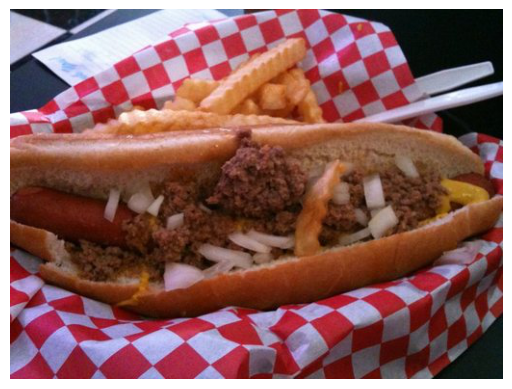

In [2]:
result = model.classify_image("hot_dog_validation/135628.jpg")

print("Class:", result["class_name"])
print("Confidence:", result["class_confidence"])
print("Очки по классам:", result["predictions"])

picture = plt.imread("hot_dog_validation/135628.jpg")
plt.imshow(picture)
plt.axis("off")
plt.show()

### Перебираем все фотки и считаем точность

In [3]:
correct = 0
total = 0
mistakes = []
answers = []

for folder, true_index in [("hot_dog_validation", 0), ("not_hot_dog_validation", 1)]:
    files = sorted(os.listdir(folder))
    good = 0

    for file_name in files:
        result = model.classify_image(os.path.join(folder, file_name))
        answers.append((true_index, result["predictions"]))
        total += 1
        if result["class_index"] == true_index:
            good += 1
            correct += 1
        else:
            mistakes.append((file_name, result["class_name"], result["class_confidence"]))

    print(folder, "->", good, "из", len(files), "правильно")

print()
print("Вместе:", correct, "из", total, "->", round(correct / total * 100, 1), "%")

hot_dog_validation -> 218 из 250 правильно


not_hot_dog_validation -> 222 из 250 правильно

Вместе: 440 из 500 -> 88.0 %


In [4]:
print("Ошибки:")
for file_name, class_name, confidence in mistakes:
    print(" ", file_name, "->", class_name, round(confidence * 100, 1), "%")

Ошибки:
  154409.jpg -> 1 не хот-доги 100.0 %
  189511.jpg -> 1 не хот-доги 85.5 %
  207335.jpg -> 1 не хот-доги 97.9 %
  211824.jpg -> 1 не хот-доги 99.9 %
  219273.jpg -> 1 не хот-доги 96.0 %
  259058.jpg -> 1 не хот-доги 99.6 %
  291354.jpg -> 1 не хот-доги 99.7 %
  315747.jpg -> 1 не хот-доги 99.5 %
  397696.jpg -> 1 не хот-доги 99.9 %
  398941.jpg -> 1 не хот-доги 84.2 %
  403561.jpg -> 1 не хот-доги 99.9 %
  413825.jpg -> 1 не хот-доги 91.1 %
  493727.jpg -> 1 не хот-доги 100.0 %
  498141.jpg -> 1 не хот-доги 100.0 %
  502977.jpg -> 1 не хот-доги 98.4 %
  505563.jpg -> 1 не хот-доги 56.2 %
  505584.jpg -> 1 не хот-доги 100.0 %
  520905.jpg -> 1 не хот-доги 98.5 %
  527074.jpg -> 1 не хот-доги 100.0 %
  566965.jpg -> 1 не хот-доги 99.8 %
  570799.jpg -> 1 не хот-доги 72.7 %
  583811.jpg -> 1 не хот-доги 100.0 %
  593867.jpg -> 1 не хот-доги 100.0 %
  602204.jpg -> 1 не хот-доги 99.9 %
  607287.jpg -> 1 не хот-доги 91.2 %
  607289.jpg -> 1 не хот-доги 100.0 %
  651101.jpg -> 1 не х

### Метрики
MAE, RMSE и R2 обычно считают для регрессии, но и тут можно: сравниваем очки модели с идеальными - у правильного класса должна быть 1, у остальных 0.

In [5]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

y_true = []
y_pred = []
for true_index, scores in answers:
    for j in range(len(scores)):
        y_true.append(1 if j == true_index else 0)
        y_pred.append(float(scores[j]))

print("MAE:", round(mean_absolute_error(y_true, y_pred), 4))
print("RMSE:", round(mean_squared_error(y_true, y_pred) ** 0.5, 4))
print("R2:", round(r2_score(y_true, y_pred), 4))

MAE: 0.1282
RMSE: 0.3315
R2: 0.5604


### Скриншоты с сайта

Классы на сайте: хот-доги и не хот-доги, по 249 фоток в каждом.

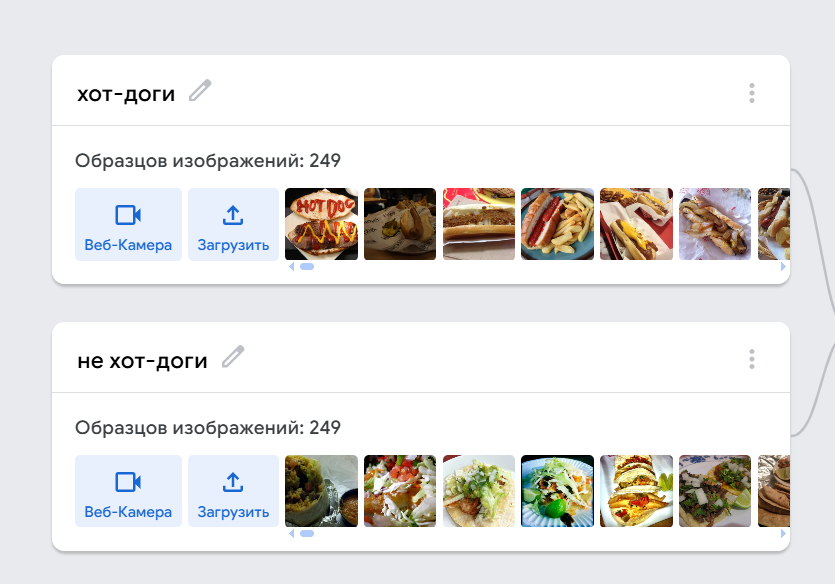

In [6]:
from IPython.display import Image, display
display(Image("screenshots/01_classes.png", width=668))

Точность по классам, которую показал сам сайт: хот-доги 0.79, не хот-доги 0.82.
Проверял он на 38 фотках каждого класса.

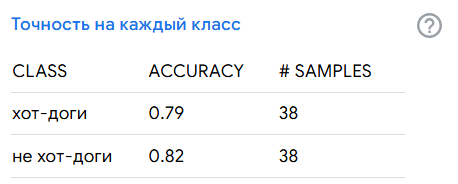

In [7]:
display(Image("screenshots/02_accuracy_per_class.png", width=420))

Матрица ошибок: из хот-догов 30 узнала, 8 пропустила, из не хот-догов 31 узнала, 7 пропустила.

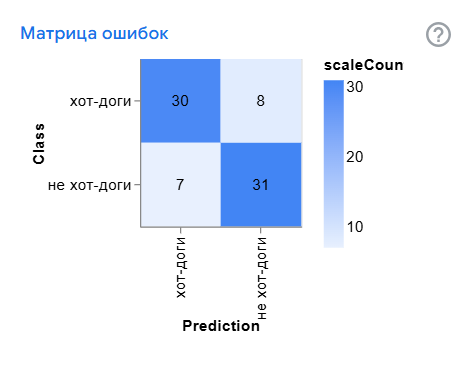

In [8]:
display(Image("screenshots/03_confusion_matrix.png", width=420))

Как менялись точность и потеря по эпохам обучения.

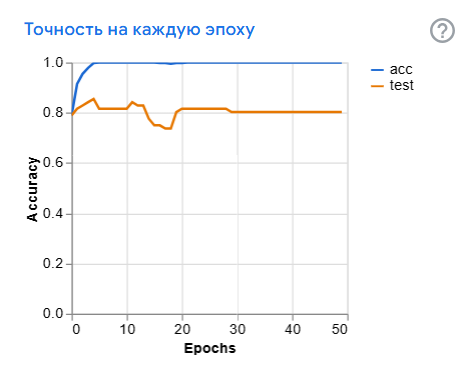

In [9]:
display(Image("screenshots/04_accuracy_per_epoch.png", width=420))

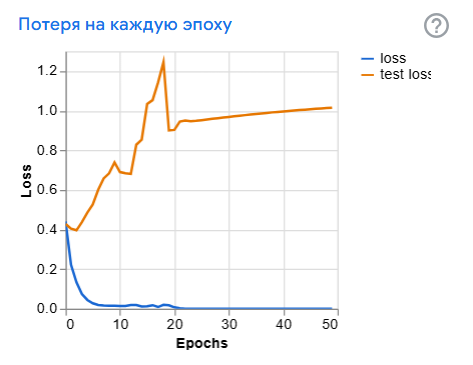

In [10]:
display(Image("screenshots/05_loss_per_epoch.png", width=420))

Проверили в разделе "Посмотреть" на сайте: стейк она назвала не хот-догом (100%),
а хот-дог узнала (100%).

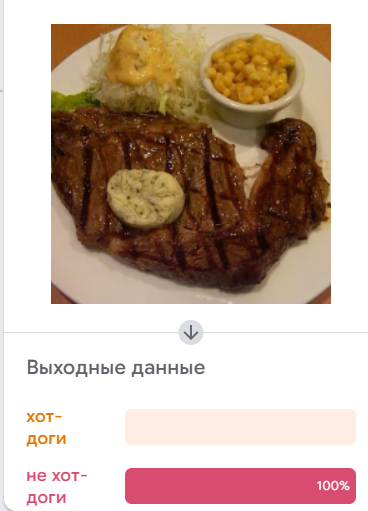

In [11]:
display(Image("screenshots/06_example_not_hot_dog.png", width=300))

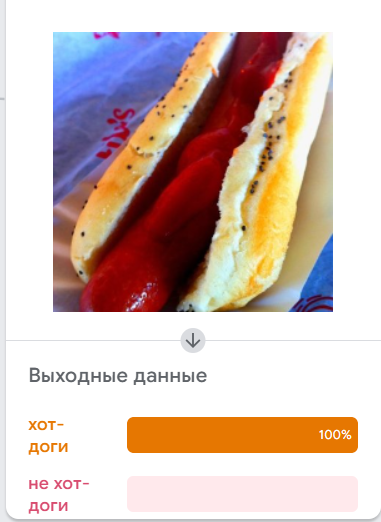

In [12]:
display(Image("screenshots/07_example_hot_dog.png", width=300))

### Вывод по Заданию 1

Посчитали: хот-доги 218 из 250 = 87.2%, не хот-доги 222 из 250 = 88.8%.
Вместе 440 из 500 = 88.0%, то есть 60 ошибок.
Посмотрели ошибки: 44 из 60 модель сделала с уверенностью 95% и выше, некоторые даже 100%.
То есть она не сомневается, а уверенно путает похожую еду.
Почему так: в обучении (hot_dog_train) в основном классический хот-дог в булке, а в проверке
попались крупные планы, где булка сливается с другой едой - стейки, сэндвичи, тако.
Сайт на своём тесте показал примерно то же: 0.79 и 0.82.

# Задание 2

Для второго задания мы собрали свои фотки: ручки, карандаши и фломастеры (28, 23 и 21 штуку).
Обучили на сайте, модель скачали тоже в Keras.

### Скриншоты с сайта

Классы: ручки 28 фоток, карандаши 23, фломастеры 21. Настройки обучения оставили как были:
50 эпох, пакет 16, скорость обучения 0,001.

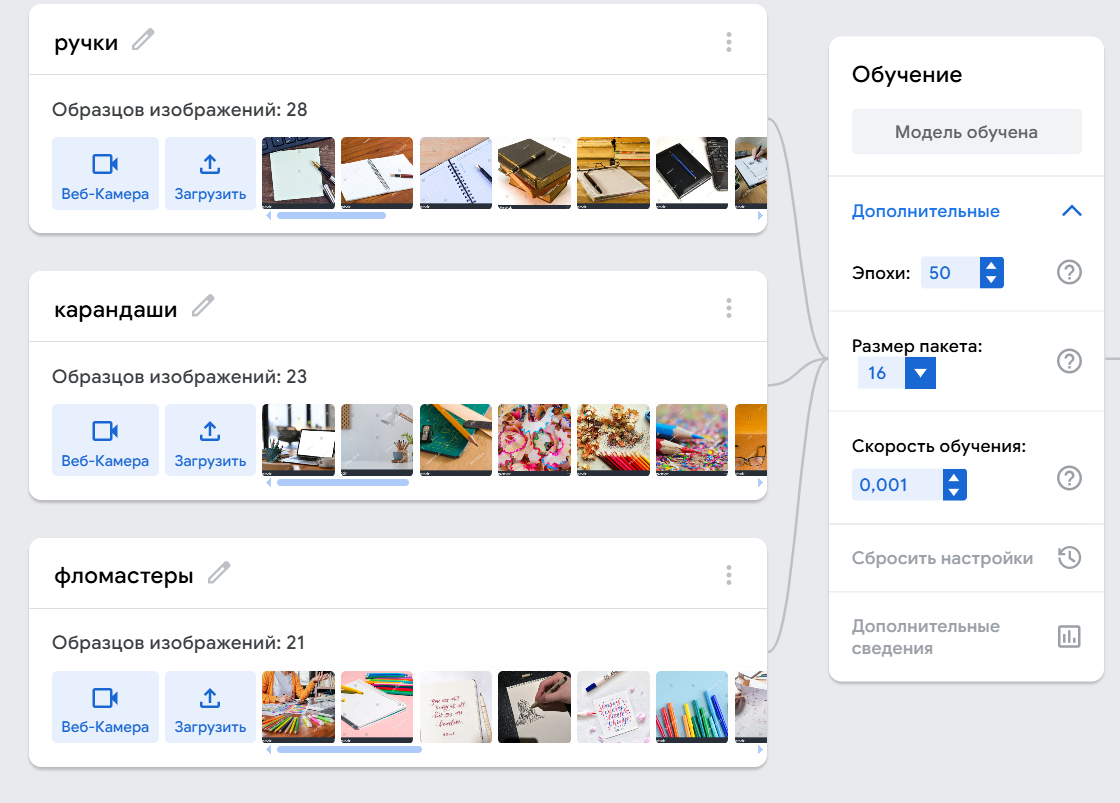

In [13]:
from IPython.display import Image, display
display(Image("screenshots/task2_01_classes.png", width=668))

Что показал сайт на своём тесте: ручки 0.80 (5 фоток), карандаши 0.75 (4), фломастеры 0.50 (4).
Тест у сайта маленький, поэтому цифры скачут.

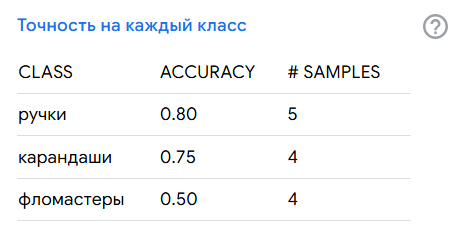

In [14]:
display(Image("screenshots/task2_02_accuracy_per_class.png", width=420))

Матрица ошибок: ручки 4 верно и 1 ошибка, карандаши 3 верно и 1 ошибка, фломастеры 2 верно
и 2 ошибки. Фломастеры модель путает в основном с карандашами.

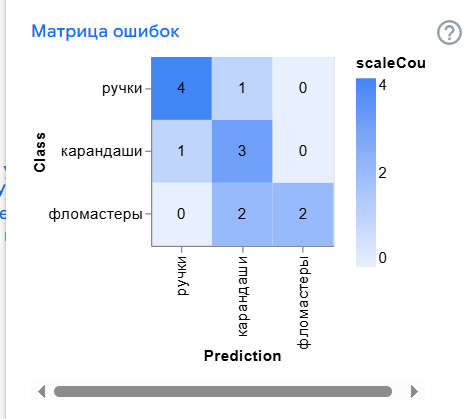

In [15]:
display(Image("screenshots/task2_03_confusion_matrix.png", width=420))

Точность и потеря по эпохам. На обучении точность быстро стала 1, а на тесте
держалась около 0.7 - уже тут видно, что модель запомнила обучающие фотки.

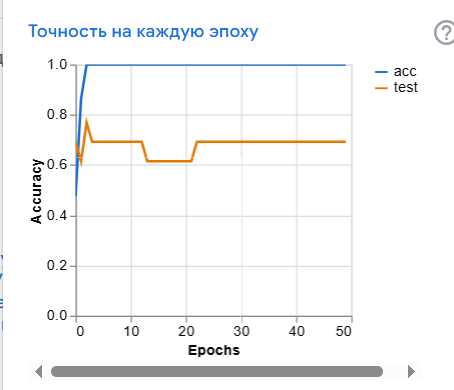

In [16]:
display(Image("screenshots/task2_04_accuracy_per_epoch.png", width=420))

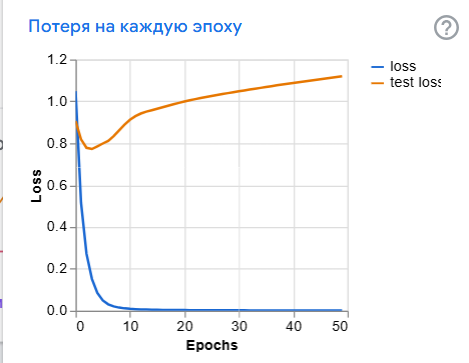

In [17]:
display(Image("screenshots/task2_05_loss_per_epoch.png", width=420))

In [18]:
model2 = TeachableMachine(
    model_path="task2_model/keras_model.h5",
    labels_file_path="task2_model/labels.txt",
)

labels = []
for line in open("task2_model/labels.txt", "r", encoding="utf-8"):
    labels.append(line.strip().split(" ", 1))

folders = {"ручки": "task2/pen", "карандаши": "task2/pencil", "фломастеры": "task2/marker"}

for index, class_name in labels:
    print("Класс", index, "->", class_name, ":", len(os.listdir(folders[class_name])), "файлов")

Teachable Machine Object is created successfully.
Класс 0 -> ручки : 28 файлов
Класс 1 -> карандаши : 23 файлов
Класс 2 -> фломастеры : 21 файлов


### Точность на обучающих фотках

In [19]:
correct = 0
total = 0
mistakes = []
answers = []

for index, class_name in labels:
    folder = folders[class_name]
    files = sorted(os.listdir(folder))
    good = 0

    for file_name in files:
        result = model2.classify_image(os.path.join(folder, file_name))
        answers.append((int(index), result["predictions"]))
        total += 1
        if result["class_index"] == int(index):
            good += 1
            correct += 1
        else:
            mistakes.append((folder, file_name, result["class_name"], result["class_confidence"]))

    print(class_name, "->", good, "из", len(files), "правильно =", round(good / len(files) * 100, 1), "%")

print()
print("Вместе:", correct, "из", total, "->", round(correct / total * 100, 1), "%")

ручки -> 27 из 28 правильно = 96.4 %


карандаши -> 21 из 23 правильно = 91.3 %


фломастеры -> 19 из 21 правильно = 90.5 %

Вместе: 67 из 72 -> 93.1 %


In [20]:
print("Ошибки:")
for folder, file_name, predicted, confidence in mistakes:
    print(" ", folder + "/" + file_name, "->", predicted, round(confidence * 100, 1), "%")

Ошибки:
  task2/pen/pen_011.jpg -> 1 карандаши 51.1 %
  task2/pencil/pencil_020.jpg -> 0 ручки 86.4 %
  task2/pencil/pencil_024.jpg -> 2 фломастеры 55.4 %
  task2/marker/marker_021.jpg -> 1 карандаши 99.9 %
  task2/marker/marker_027.jpg -> 0 ручки 35.1 %


### Метрики на обучающих фотках
Те же MAE, RMSE и R2 по очкам уверенности: идеально 1 у правильного класса и 0 у остальных.

In [21]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

y_true = []
y_pred = []
for true_index, scores in answers:
    for j in range(len(scores)):
        y_true.append(1 if j == true_index else 0)
        y_pred.append(float(scores[j]))

print("MAE:", round(mean_absolute_error(y_true, y_pred), 4))
print("RMSE:", round(mean_squared_error(y_true, y_pred) ** 0.5, 4))
print("R2:", round(r2_score(y_true, y_pred), 4))

MAE: 0.042
RMSE: 0.1626
R2: 0.881


### Проверка на новых фотках
В папках pen_test, pencil_test и marker_test лежат снимки, которых модель не видела при обучении.
Это и есть честная проверка.
Эту проверку прогнали на обновлённой модели: после первой проверки дообучили на сайте
и скачали новый Keras.

In [3]:
# проверку прогоняем на обновлённой модели, скачанной после дообучения на сайте
model2 = TeachableMachine(
    model_path="task2_model_new/keras_model.h5",
    labels_file_path="task2_model_new/labels.txt",
)

correct = 0
total = 0
mistakes = []
answers_test = []

for index, class_name in labels:
    folder = folders[class_name] + "_test"
    files = sorted(os.listdir(folder))
    good = 0

    for file_name in files:
        result = model2.classify_image(os.path.join(folder, file_name))
        answers_test.append((int(index), result["predictions"]))
        total += 1
        if result["class_index"] == int(index):
            good += 1
            correct += 1
        else:
            mistakes.append((folder, file_name, result["class_name"], result["class_confidence"]))

    print(folder, "->", good, "из", len(files), "правильно =", round(good / len(files) * 100, 1), "%")

print()
print("Вместе:", correct, "из", total, "->", round(correct / total * 100, 1), "%")

Teachable Machine Object is created successfully.


task2/pen_test -> 3 из 4 правильно = 75.0 %


task2/pencil_test -> 1 из 3 правильно = 33.3 %


task2/marker_test -> 3 из 3 правильно = 100.0 %

Вместе: 7 из 10 -> 70.0 %


In [4]:
print("Ошибки:")
for folder, file_name, predicted, confidence in mistakes:
    print(" ", folder + "/" + file_name, "->", predicted, round(confidence * 100, 1), "%")

Ошибки:
  task2/pen_test/pen_test_002.jpg -> 1 карандаши 51.9 %
  task2/pencil_test/pencil_test_001.jpg -> 0 ручки 95.2 %
  task2/pencil_test/pencil_test_002.jpg -> 2 фломастеры 97.3 %


### Метрики на новых фотках
И те же метрики на честной проверке. Ошибки выросли, а R2 упал с 0.881 до 0.3094 -
на новых фотках модель считает хуже, чем на обучающих.

In [5]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

y_true = []
y_pred = []
for true_index, scores in answers_test:
    for j in range(len(scores)):
        y_true.append(1 if j == true_index else 0)
        y_pred.append(float(scores[j]))

print("MAE:", round(mean_absolute_error(y_true, y_pred), 4))
print("RMSE:", round(mean_squared_error(y_true, y_pred) ** 0.5, 4))
print("R2:", round(r2_score(y_true, y_pred), 4))

MAE: 0.2015
RMSE: 0.3918
R2: 0.3094


### Смотрим одну ошибку глазами
Берём первую ошибку из списка и смотрим на саму фотку.

Файл: task2/pen_test\pen_test_002.jpg
Ответ модели: 1 карандаши -> 51.9 %
Очки по классам: [0.481, 0.519, 0.001]


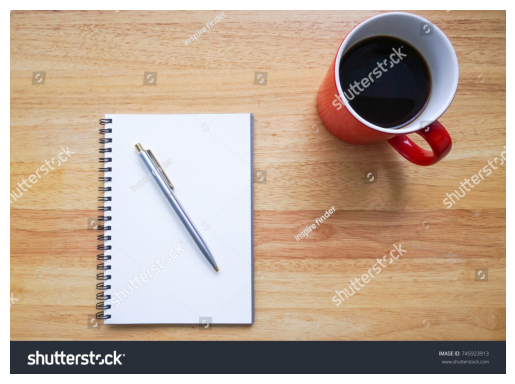

In [6]:
if mistakes:
    folder, file_name = mistakes[0][0], mistakes[0][1]
else:
    folder = folders[labels[0][1]] + "_test"
    file_name = sorted(os.listdir(folder))[0]

path = os.path.join(folder, file_name)
result = model2.classify_image(path)

print("Файл:", path)
print("Ответ модели:", result["class_name"], "->", round(result["class_confidence"] * 100, 1), "%")
print("Очки по классам:", [round(float(x), 3) for x in result["predictions"]])

picture = plt.imread(path)
plt.imshow(picture)
plt.axis("off")
plt.show()

### Вывод по Заданию 2

На обучающих фотках 67 из 72 = 93.1% (ручки 96.4%, карандаши 91.3%, фломастеры 90.5%).
Но эти фотки модель видела при обучении, поэтому цифра завышена.
На новых фотках 7 из 10 = 70.0%: ручки 3 из 4, карандаши 1 из 3, фломастеры 3 из 3.
Вот это настоящая точность. Сайт на своём тесте после первого обучения показал 9 из 13 = 69.2%,
то есть примерно то же. Путается модель между всеми тремя классами: они все тонкие палочки
для письма. Смотрит она не столько на предмет, сколько на обстановку: карандаш в руке плотника
назвала ручкой (95.2%), жёлтый карандаш на доске - фломастером (97.3%). А металлическую ручку
с фотки с кофе приняла за карандаш, причём очки почти равные (51.9% против 48.1% и 0.1%) -
модель не узнала предмет и угадывала. В обучении были крупные планы предмета на столе,
а в проверке сцены с руками и доской, таких кадров она не видела.

# Задание 3

# Pocket AutoML: мячи на смартфоне

Приложение Pocket AutoML поставили на телефон и обучали прямо там. Интернет для тренировки
не нужен, модель считает на телефоне. Классов сделали три: баскетбольные мячи, боулинговые мячи,
футбольные мячи. Фотки взяли из папки task3 и закинули в галерею телефона.

Три класса, фотки загружены из галереи прямо в приложении.

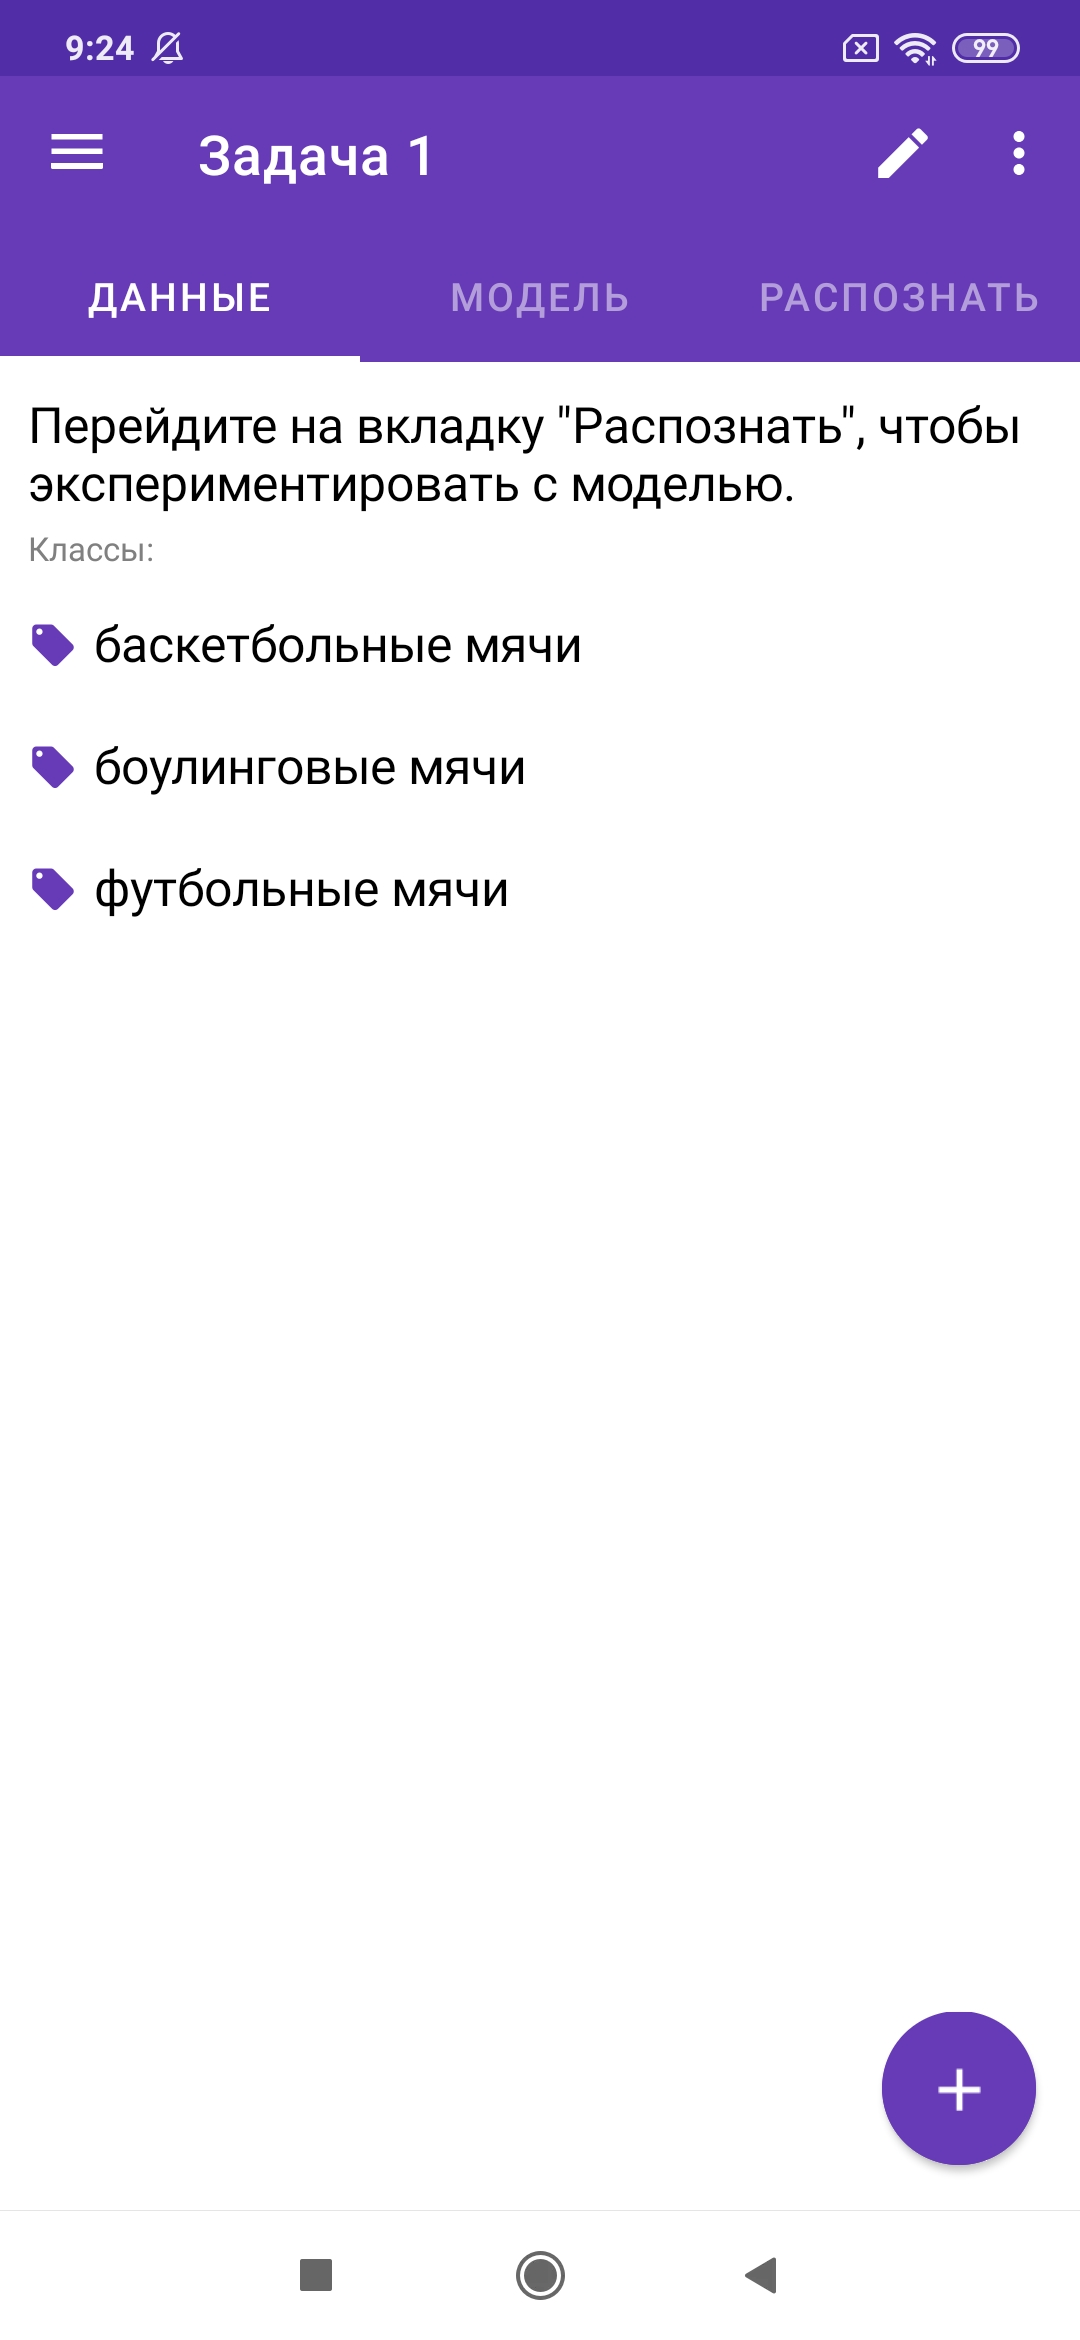

In [26]:
from IPython.display import Image, display
display(Image("screenshots/task3_01_data_classes.jpg", width=320))

Вот класс баскетбольных мячей: мяч целиком, крупные планы текстуры, мяч на траве.
Ракурсы разные, чтобы модель не запомнила одну картинку.

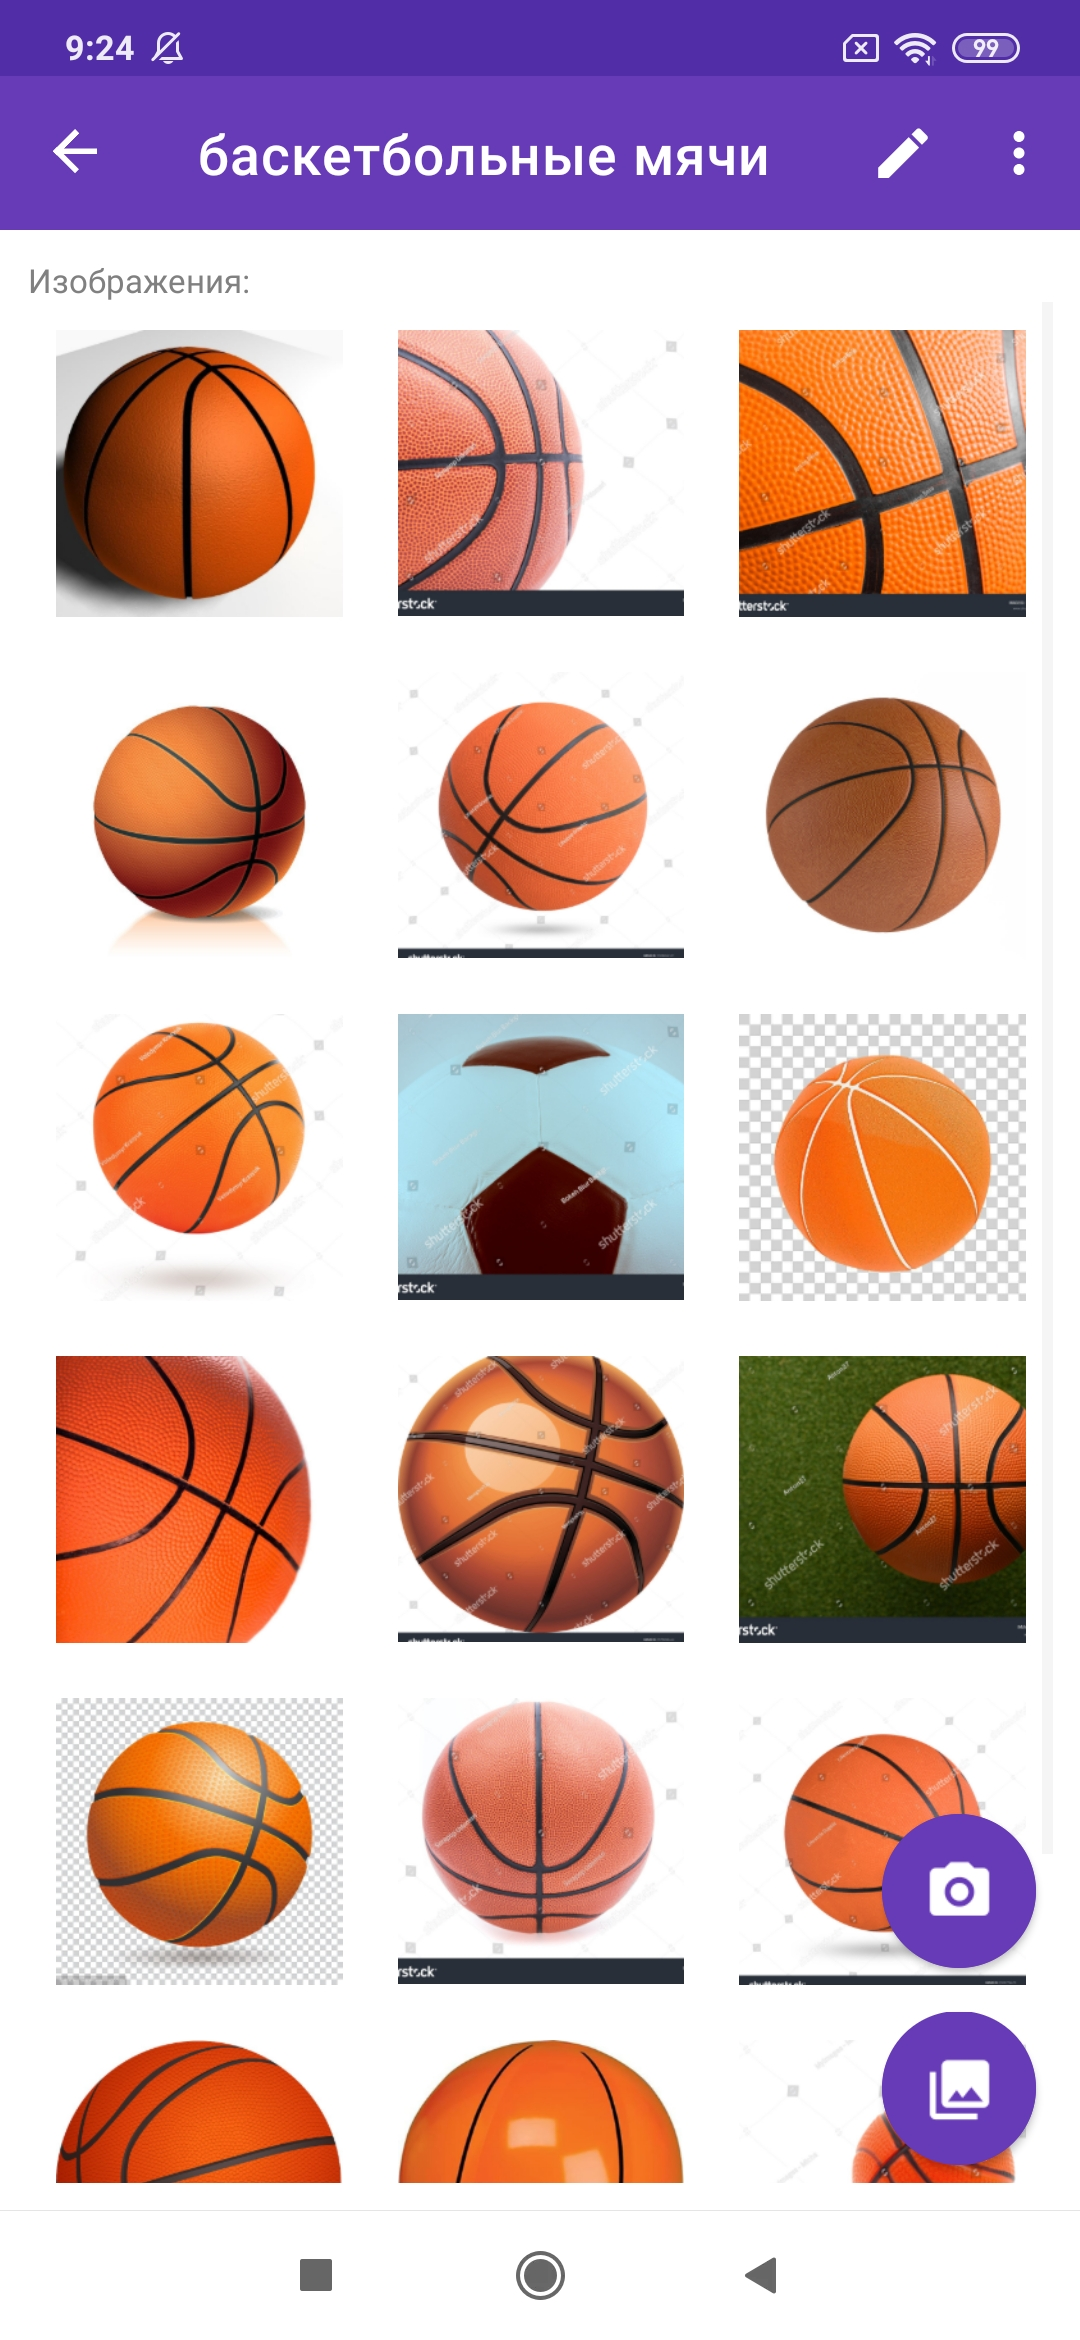

In [27]:
display(Image("screenshots/task3_02_data_basketball.jpg", width=320))

Розовый мяч для боулинга узнала сразу, нажали "Подтвердить".

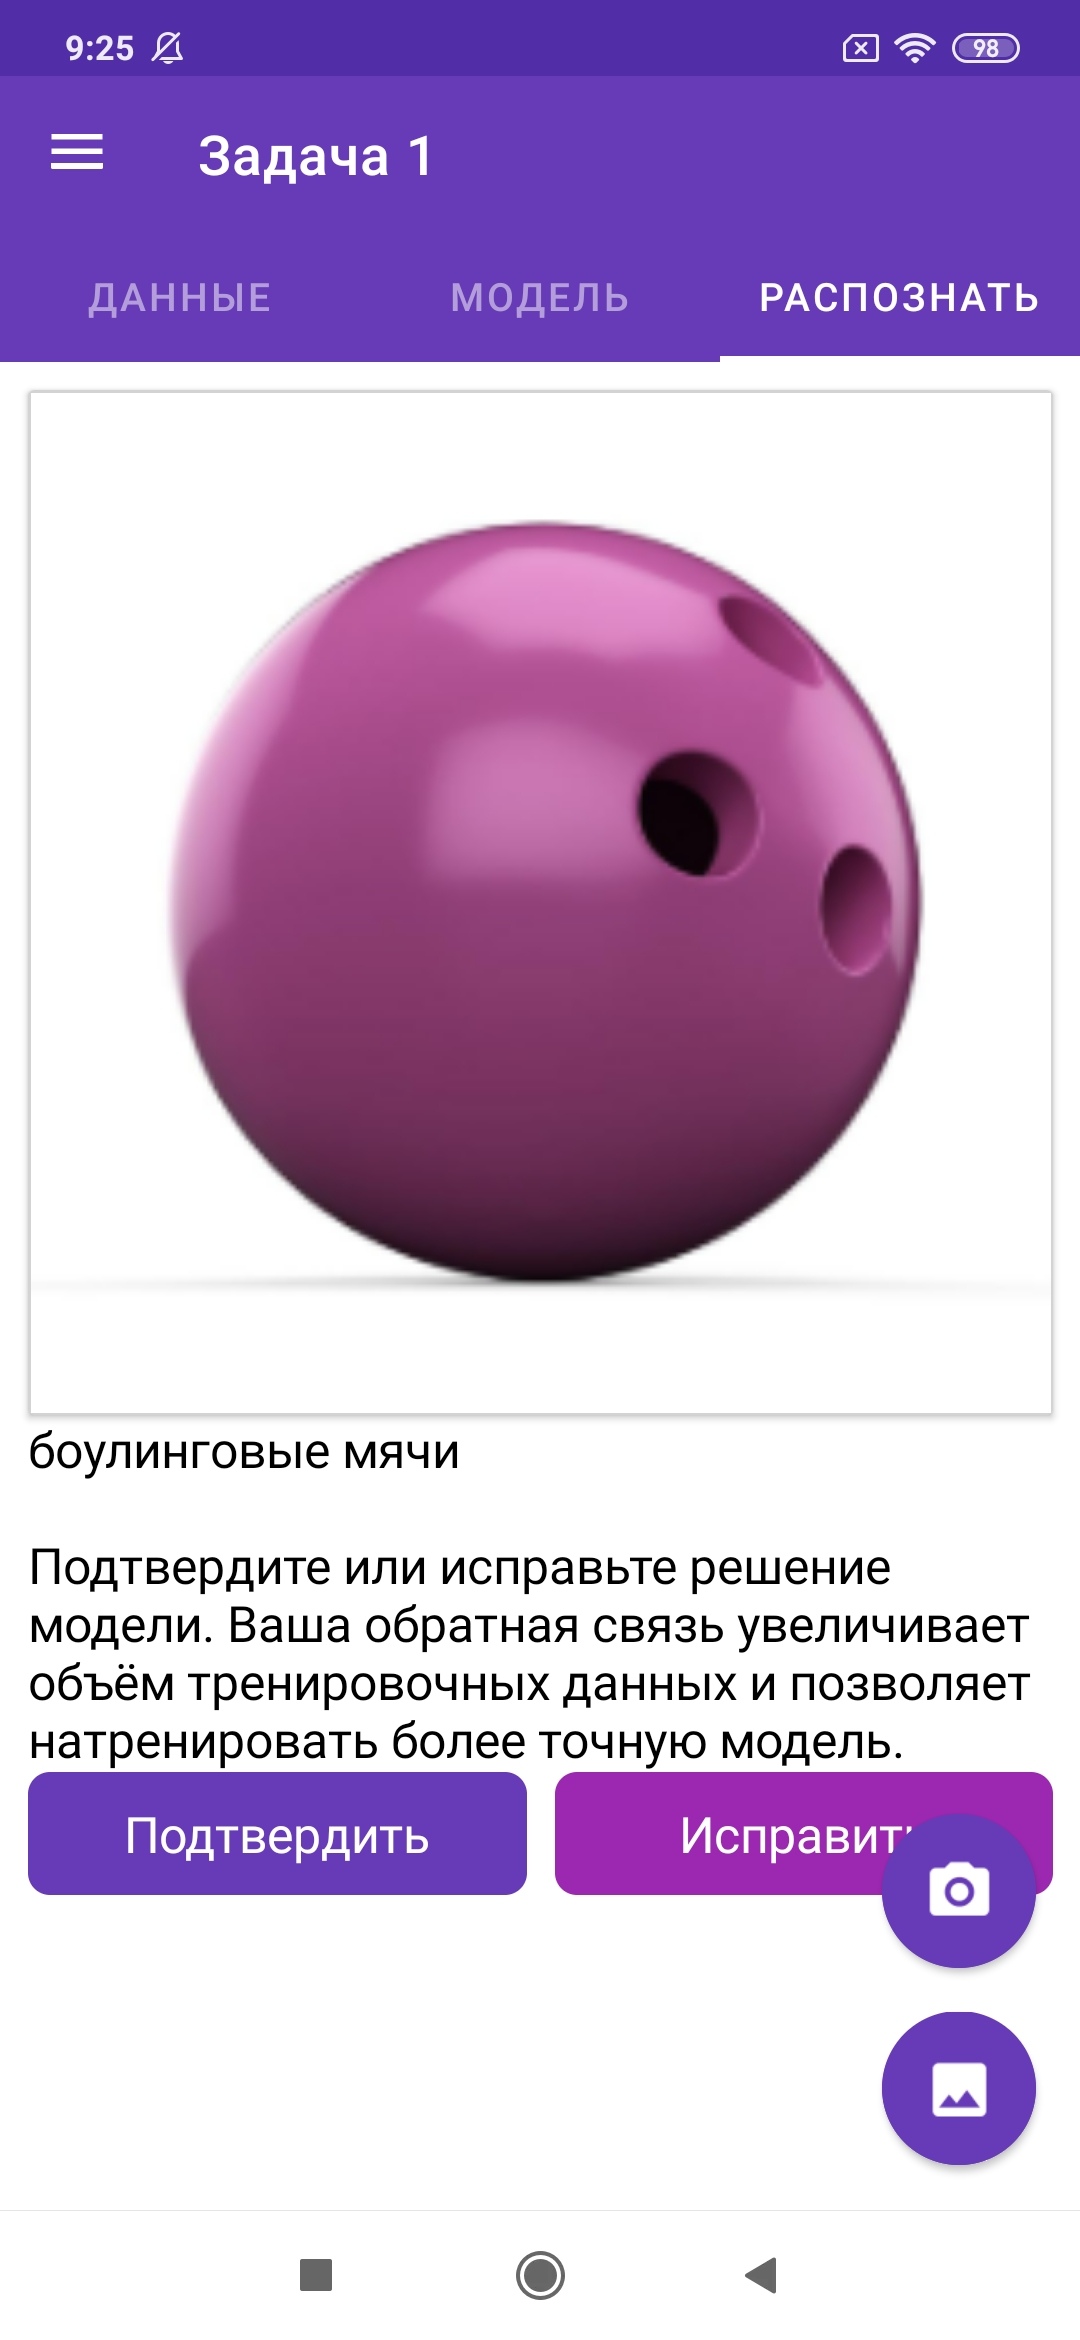

In [28]:
display(Image("screenshots/task3_03_recognize_bowling.jpg", width=320))

Футбольные мячи: мяч на детской тренировке, вокруг конусы и ноги игроков. Модель ответила
"футбольные мячи", подтвердили.

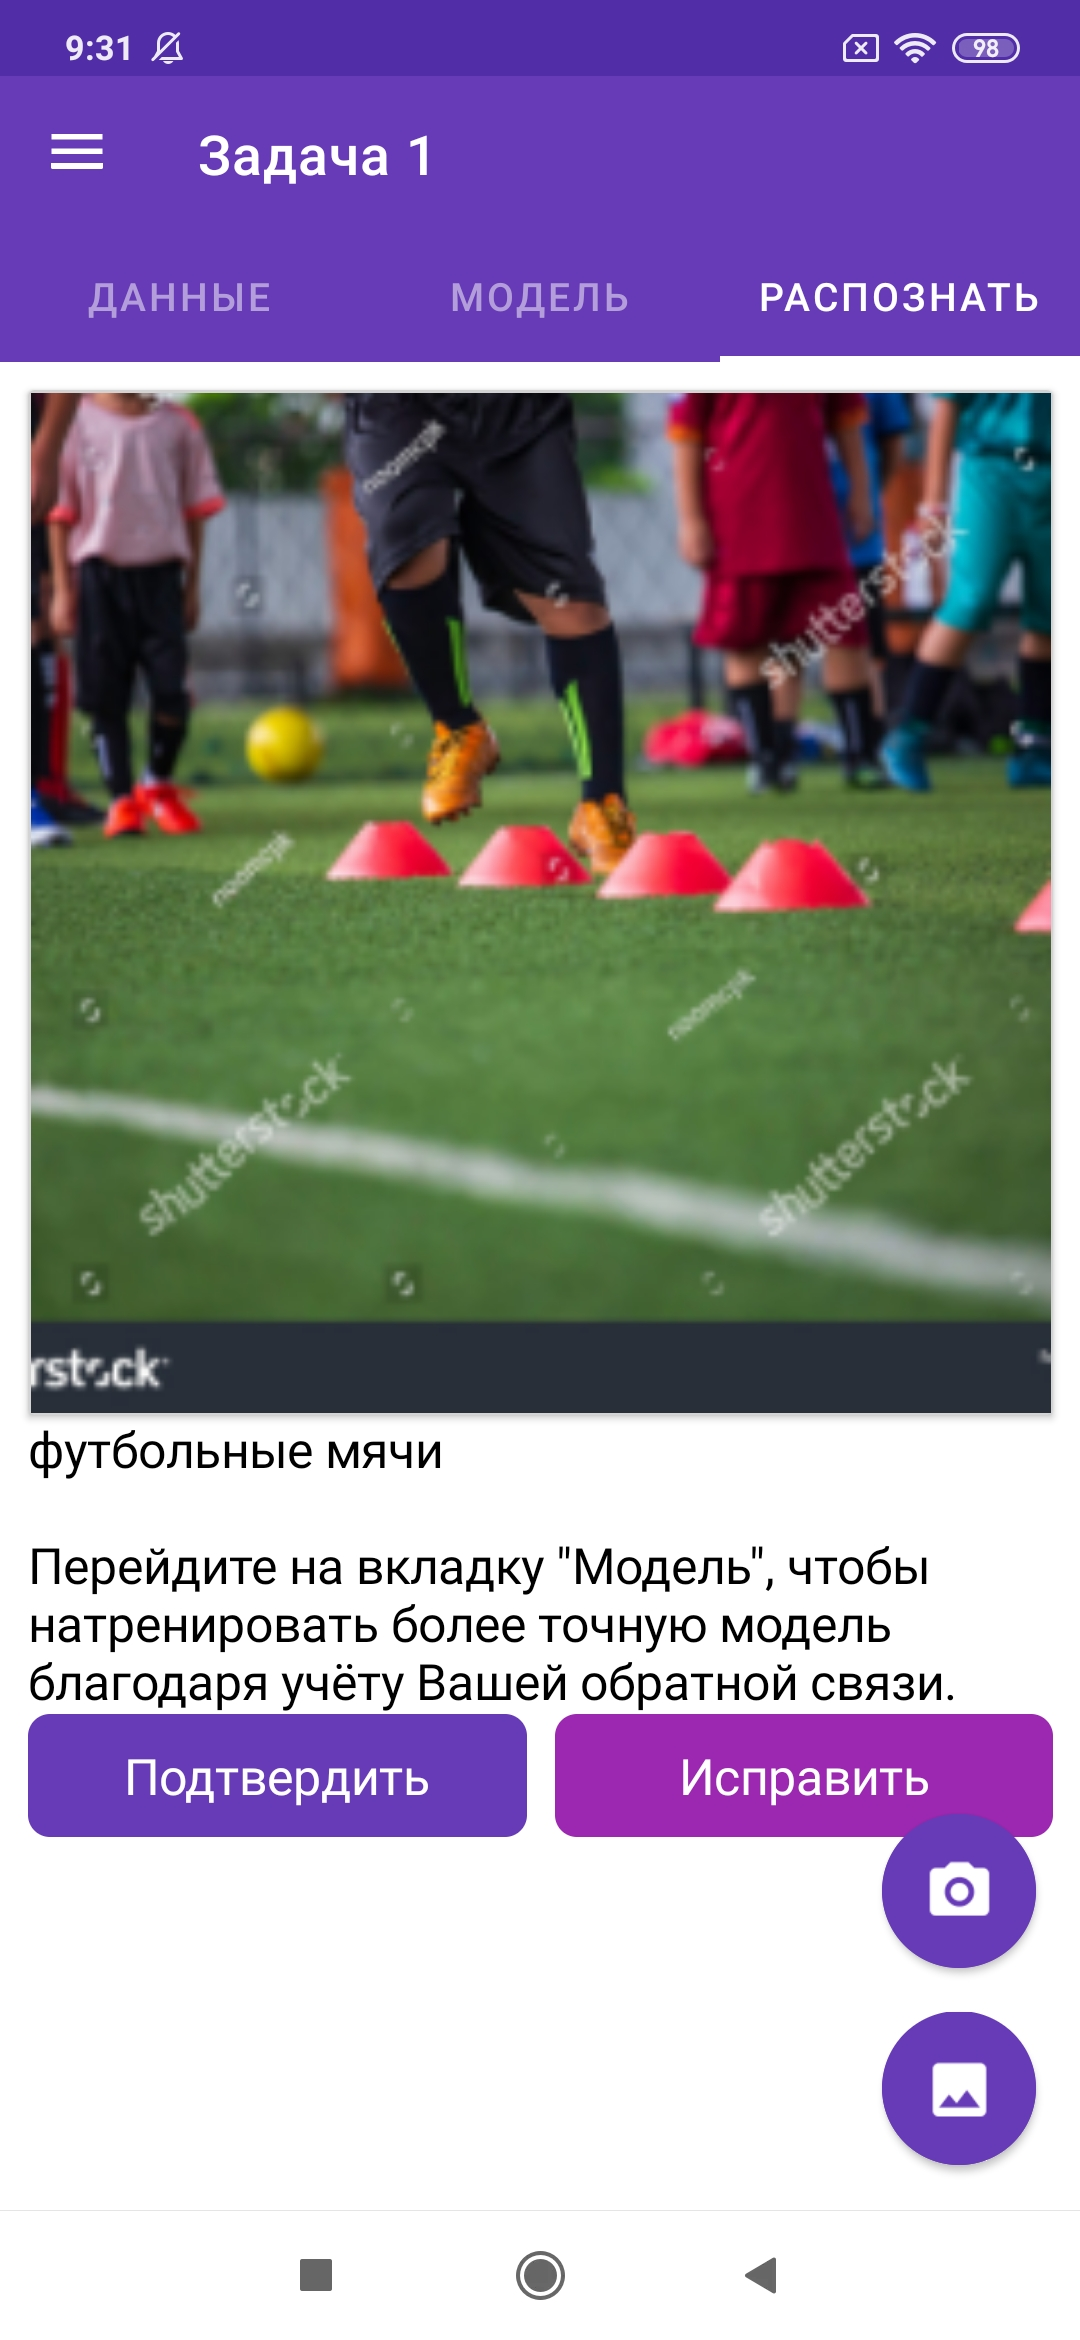

In [29]:
display(Image("screenshots/task3_04_recognize_football.jpg", width=320))

Баскетбольный мяч на траве тоже верно, подтвердили. После каждого подтверждения фотка уходит
в тренировочные данные.

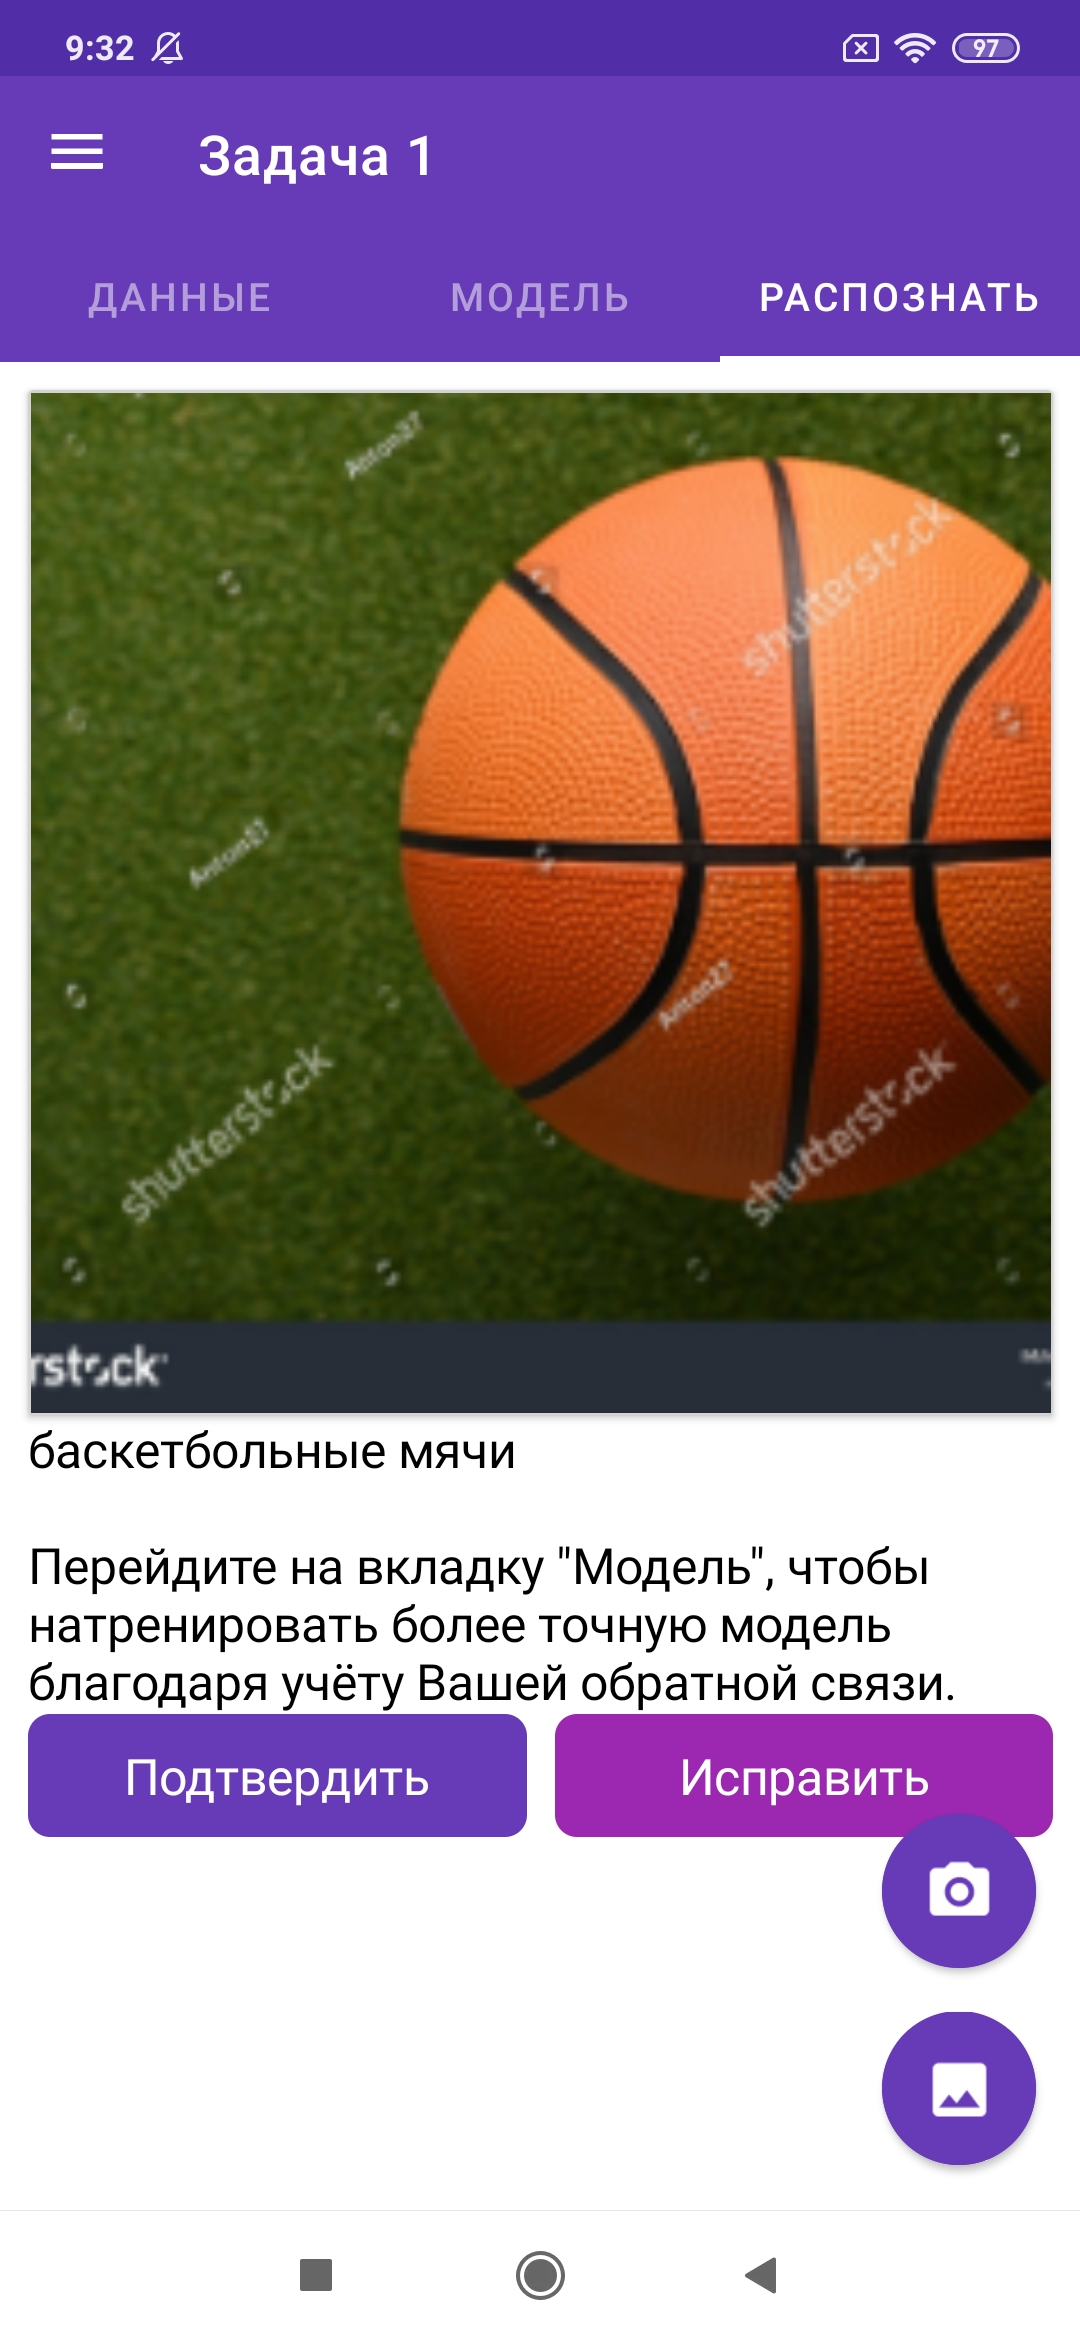

In [30]:
display(Image("screenshots/task3_05_recognize_basketball.jpg", width=320))

Приложение само считает статистику: 56 тренировочных изображений, 15 распознаваний, из них
13 подтверждены. Точность не одной цифрой, а диапазоном от 61,65% до 95,95% с 95%
достоверностью, потому что примеров всего 15. Два ответа пришлось исправить.

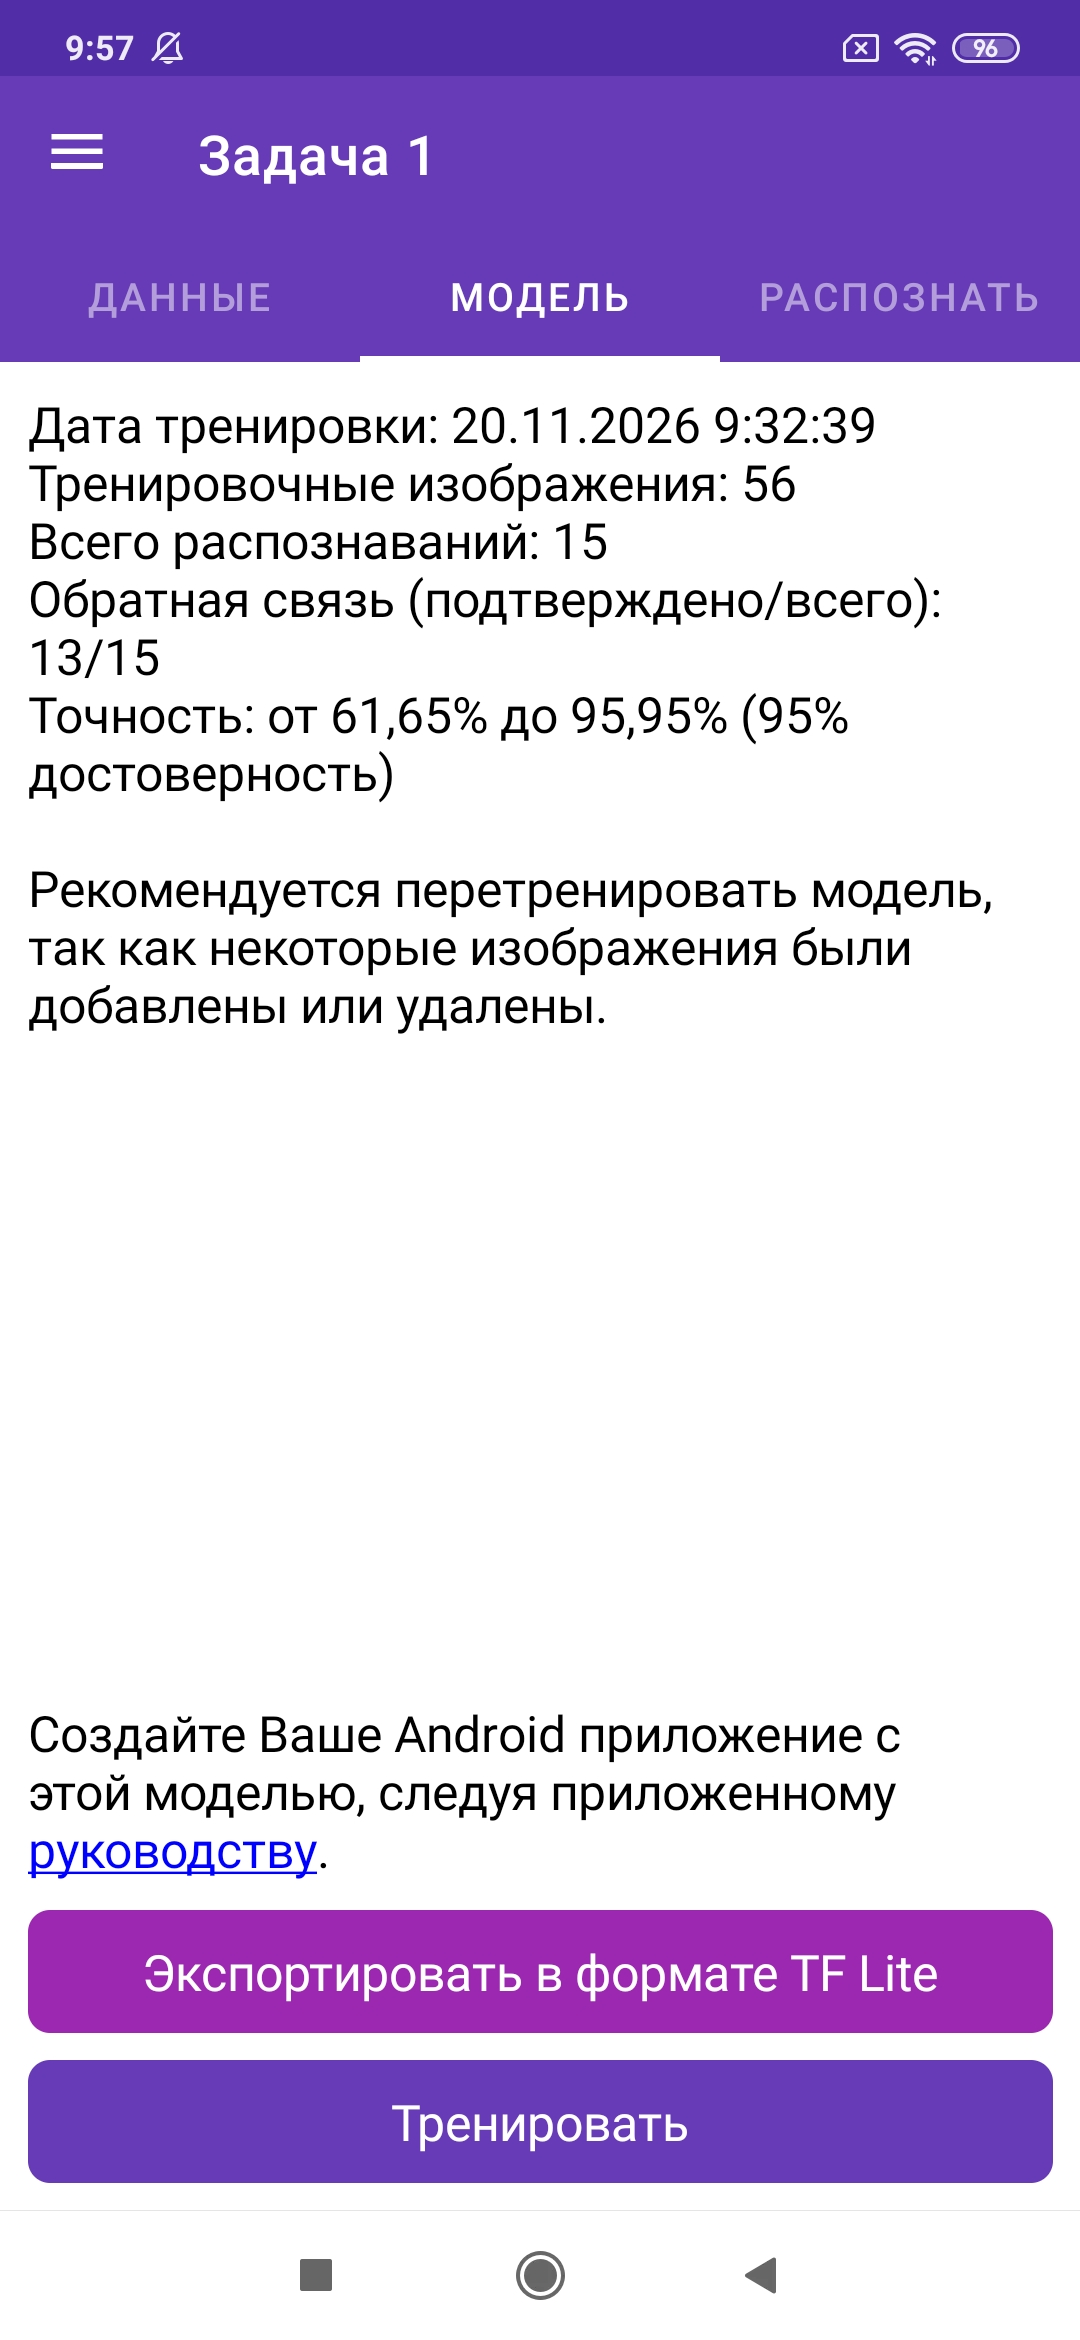

In [31]:
display(Image("screenshots/task3_06_model_round1.jpg", width=320))

Подтверждённые и исправленные фотки ушли в обучение, плюс добавили 10 проверочных снимков,
которых модель не видела. Нажали "Тренировать" ещё раз и прогнали проверочные фотки.
Стало 68 тренировочных изображений (было 56), распознаваний 25 (было 15), подтверждено 23 из 25.
Все 10 новых ответов подтверждены, то есть на невиданных фотках модель не промахнулась.

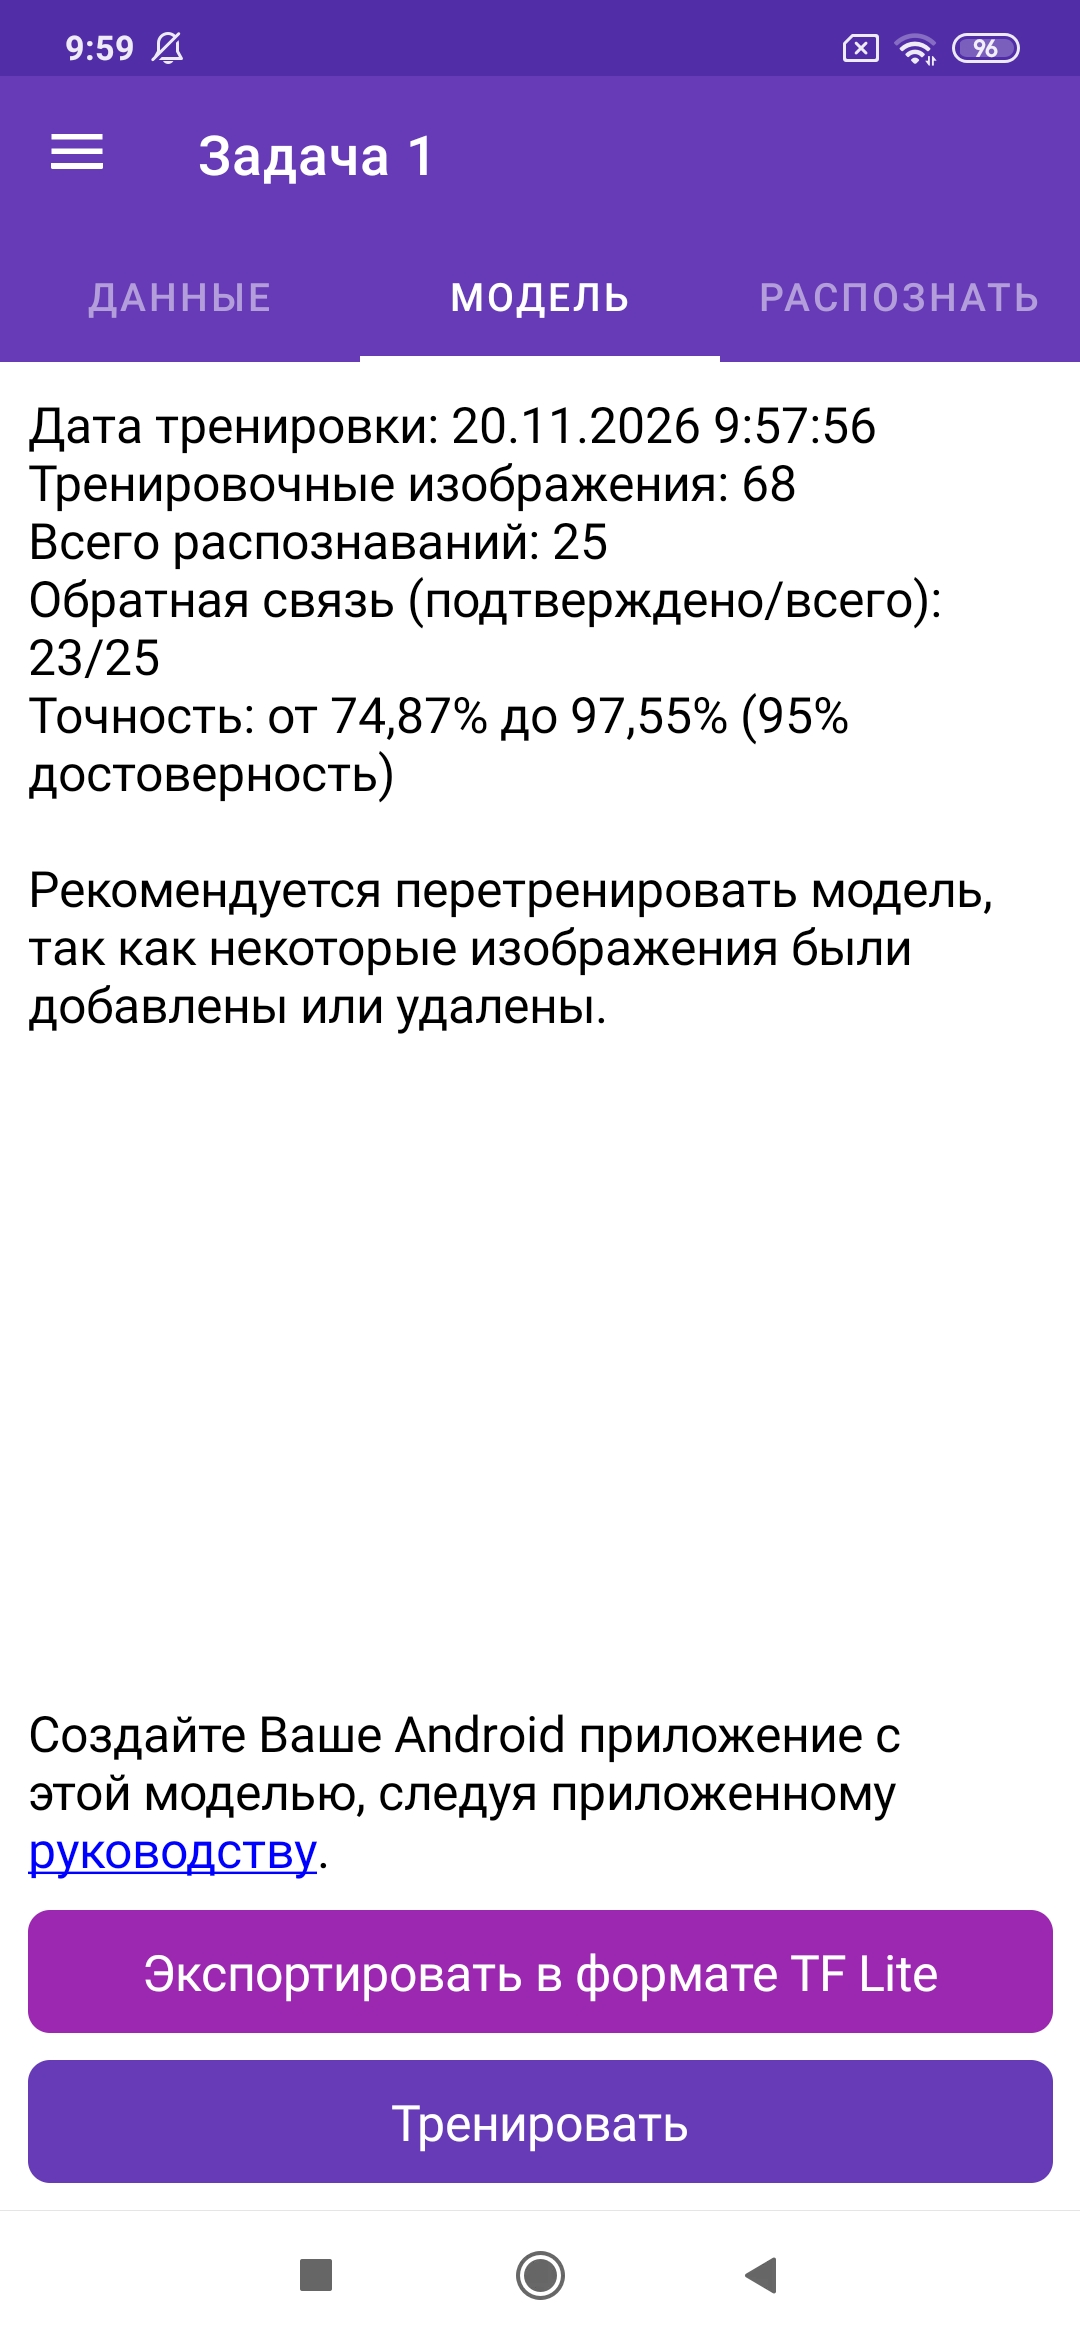

In [32]:
display(Image("screenshots/task3_07_model_round2.jpg", width=320))

### Вывод по Заданию 3

Первый круг: 56 тренировочных фото, 15 распознаваний, 13 подтверждены, точность 61.65% - 95.95%.
Второй круг после обратной связи и повторной тренировки: 68 фото, 25 распознаваний, 23 из 25
подтверждены, точность 74.87% - 97.55%.
Нижняя граница точности выросла с 61.65% до 74.87%, верхняя с 95.95% до 97.55%, подтверждённых
ответов стало 23 из 25 вместо 13 из 15. То есть модель стала реже промахиваться. На 10 проверочных
фотках, которых не было в обучении, все ответы подтверждены.
Почему диапазон, а не одна цифра: распознаваний мало (15 и 25), поэтому приложение даёт интервал
с 95% достоверностью, внутри которого лежит настоящая точность. Чем больше примеров, тем интервал
уже и выше - это и видно между кругами.

# Задание 4

# API к модели и приложение с графическим интерфейсом

Сервер встаёт на http://127.0.0.1:5055, а окно streamlit на http://127.0.0.1:8501.
Модель грузится один раз в api.py, окно само ничего не считает, только отправляет фотку
и показывает, что вернулось.

### GET: спрашиваем сервер по пути к файлу

In [33]:
import sys
sys.path.append(r"C:\Users\Рустам\Desktop\teachable_machine")
from api import app

client = app.test_client()

response = client.get("/")
print("Код:", response.status_code)
print(response.get_data(as_text=True))

Teachable Machine Object is created successfully.
Код: 200
{"classes":["\u0440\u0443\u0447\u043a\u0438","\u043a\u0430\u0440\u0430\u043d\u0434\u0430\u0448\u0438","\u0444\u043b\u043e\u043c\u0430\u0441\u0442\u0435\u0440\u044b"],"get":"/predict?path=pen_test/pen_test_001.jpg","model":"\u0440\u0443\u0447\u043a\u0438/\u043a\u0430\u0440\u0430\u043d\u0434\u0430\u0448\u0438/\u0444\u043b\u043e\u043c\u0430\u0441\u0442\u0435\u0440\u044b","post":"/predict, \u043a\u0430\u0440\u0442\u0438\u043d\u043a\u0430 \u0432 \u043f\u043e\u043b\u0435 file"}



In [34]:
response = client.get("/predict", query_string={"path": "pen_test/pen_test_003.jpg"})
data = response.get_json()

print("Код:", response.status_code)
print("Класс:", data["class"], "->", data["confidence_percent"], "%")
print("Индекс класса:", data["class_index"])
print("Очки по всем классам:")

for item in data["predictions"]:
    print("   ", item["class"], "-", item["probability"])

Код: 200
Класс: ручки -> 99.9 %
Индекс класса: 0
Очки по всем классам:
    ручки - 0.9987
    карандаши - 0.0012
    фломастеры - 0.0001


### POST: отправляем саму фотку

In [35]:
picture = open("task2/marker_test/marker_test_001.jpg", "rb")

response = client.post("/predict", data={"file": picture}, content_type="multipart/form-data")
data = response.get_json()

print("Код:", response.status_code)
print("Класс:", data["class"], "->", data["confidence_percent"], "%")
print("Очки по всем классам:")

for item in data["predictions"]:
    print("   ", item["class"], "-", item["probability"])

Код: 200
Класс: фломастеры -> 100.0 %
Очки по всем классам:
    ручки - 0.0
    карандаши - 0.0004
    фломастеры - 0.9996


Если файла нет или его не прислали, API не падает, а возвращает код и текст ошибки.

In [36]:
response = client.get("/predict", query_string={"path": "net_takogo_faila.jpg"})
print("Код:", response.status_code, response.get_json())

response = client.post("/predict", data={})
print("Код:", response.status_code, response.get_json())

Код: 404 {'error': 'файл не найден', 'path': 'net_takogo_faila.jpg'}
Код: 400 {'error': 'нет файла в поле file'}


# Изображения приложения

Вот как выглядит окно app.py 

### Шаг 1. Первоначальное окно

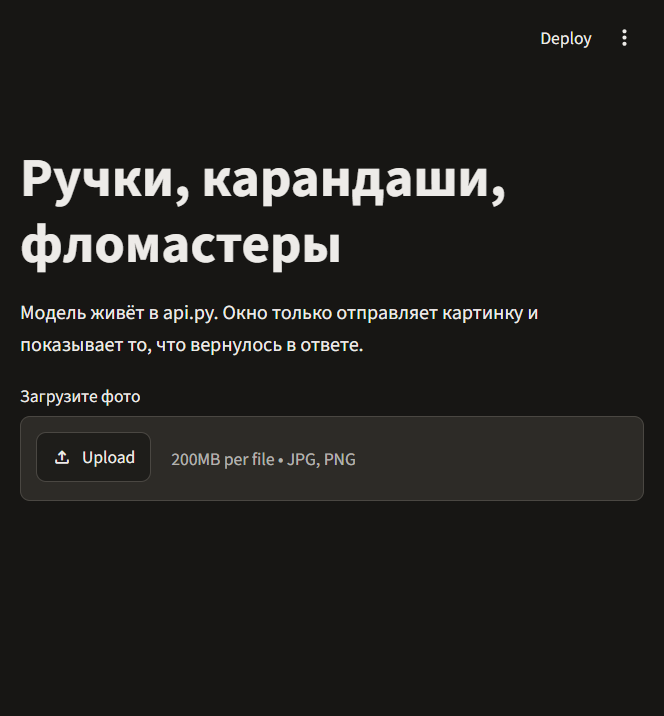

In [37]:
display(Image("screenshots/app_01_start.png", width=700))

### Шаг 2. Добавили фото

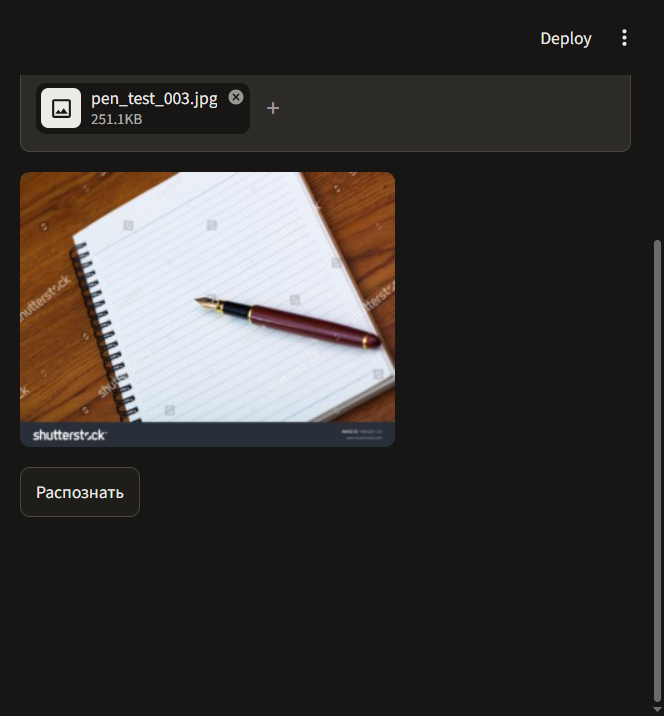

In [38]:
display(Image("screenshots/app_02_photo_loaded.png", width=700))

### Шаг 3. Ответ пришёл

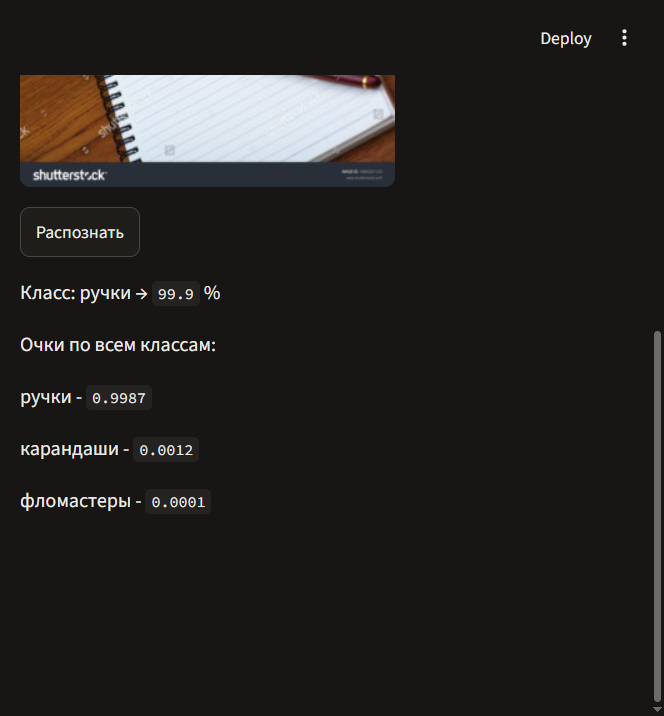

In [39]:
display(Image("screenshots/app_03_answer.png", width=460))

### Вывод по Заданию 4

Сделали api.py: отдаёт класс и точность в JSON двумя способами - GET по пути к файлу и POST
с самой фоткой. Окно app.py загружает изображение, ходит в этот API и показывает класс,
точность и очки по всем трём классам. Проверили оба запроса и ошибочные ответы - всё работает.